In [1]:
# 该银行交易行为数据有四个特征，分别表示去柜台服务、使用 Atm、刷 pos 机和信用卡的次数。
# 1、导入数据
import pandas as pd
model_data = pd.read_csv("profile_bank.csv")
data = model_data.loc[ :,'CNT_TBM':'CNT_CSC']
data.head()

,CNT_TBM,CNT_ATM,CNT_POS,CNT_CSC
0,34,3,3,9
1,44,17,5,18
2,122,26,32,36
3,42,3,6,1
4,20,15,2,2


In [2]:
# - 2、查看相关系数矩阵，判定做变量降维的必要性（非必须）
corr_matrix = data.corr(method='pearson')
#corr_matrix = corr_matrix.abs()
corr_matrix

,CNT_TBM,CNT_ATM,CNT_POS,CNT_CSC
CNT_TBM,1.000000,0.055648,0.083624,0.198835
CNT_ATM,0.055648,1.000000,0.341161,0.242106
CNT_POS,0.083624,0.341161,1.000000,0.234055
CNT_CSC,0.198835,0.242106,0.234055,1.000000


In [3]:
# - 3、做主成分之前，进行中心标准化
from sklearn import preprocessing
data = preprocessing.scale(data)

In [4]:
# - 4、使用 sklearn的主成分分析，用于判断保留主成分的数量
from sklearn.decomposition import PCA
pca=PCA(n_components=3)
newData=pca.fit(data)
print(pca.explained_variance_)
print(pca.explained_variance_ratio_)

[1.60786876 1.00252275 0.7339482 ]
[0.40196317 0.25062818 0.18348521]


In [5]:
# - 1、导入包，并对输入的数据进行主成分提取。为保险起见，data需要进行中心标准化
from fa_kit import FactorAnalysis
from fa_kit import plotting as fa_plotting
fa = FactorAnalysis.load_data_samples(data,preproc_demean=True,preproc_scale=True)
fa.extract_components()

In [6]:

# - 2、设定提取主成分的方式。默认为“broken_stick”方法，建议使用“top_n”法
fa.find_comps_to_retain(method='top_n',num_keep=3)

array([0, 1, 2], dtype=int64)

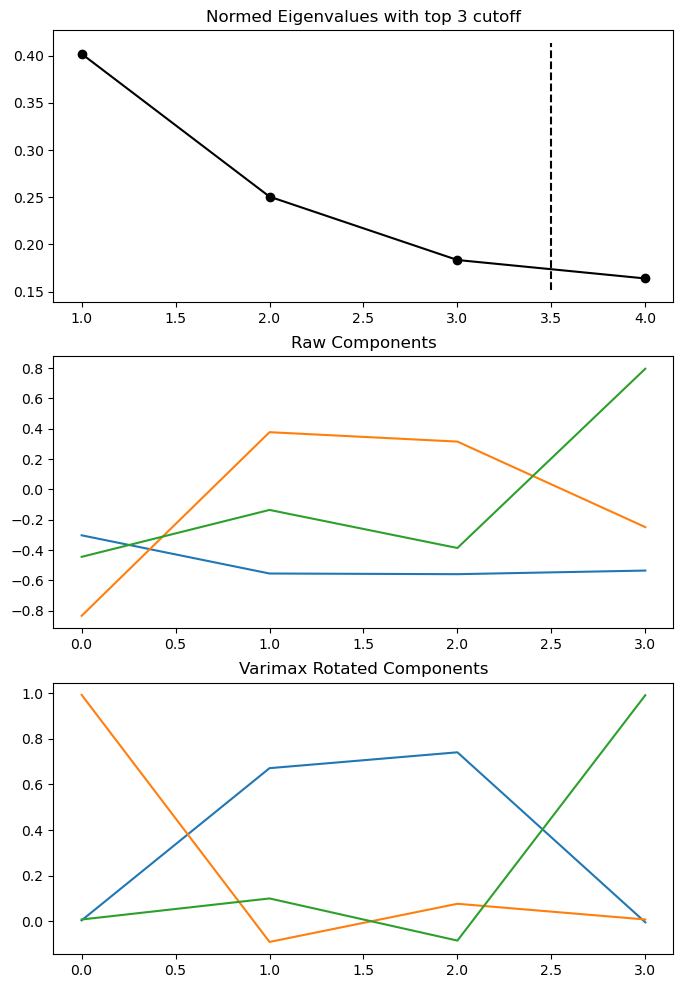

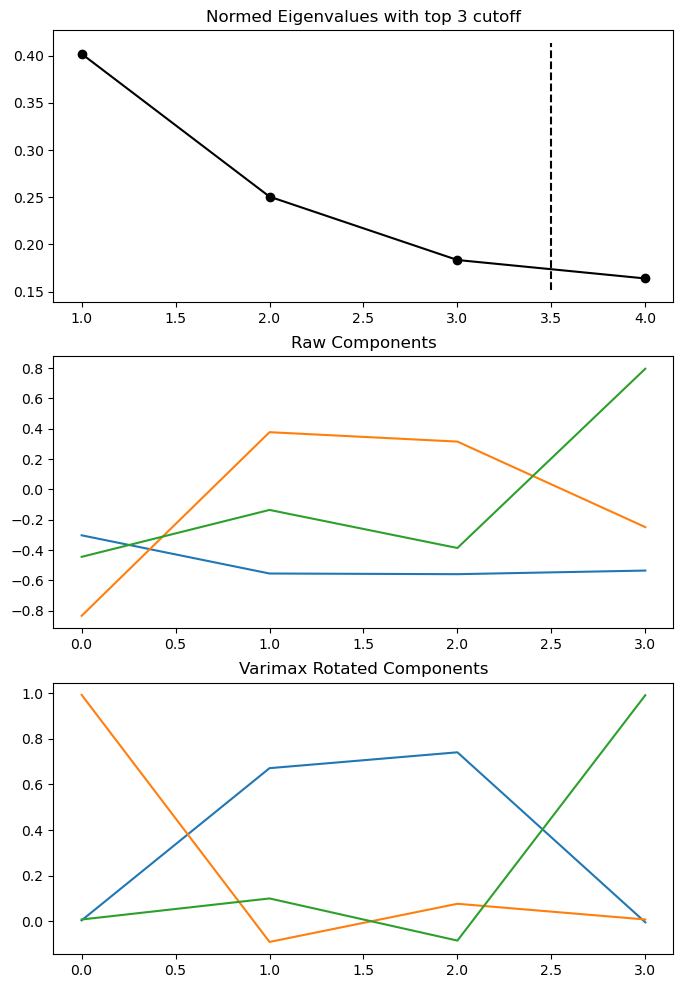

In [7]:
# - 3、通过最大方差法进行因子旋转
fa.rotate_components(method='varimax')
fa_plotting.graph_summary(fa)

In [8]:
# - 4、获取因子得分
pd.DataFrame(fa.comps["rot"])

,0,1,2
0,0.004039,0.992900,0.007811
1,0.671476,-0.090569,0.100081
2,0.741002,0.076706,-0.084707
3,-0.004504,0.007874,0.991336


In [9]:
score=fa.get_component_scores(data)
score=pd.DataFrame(score)


In [10]:

fa_scores=score.rename(columns={0: "ATM_POS", 1: "TBM",2: "CSC"})

In [11]:
fa_scores.head()

,ATM_POS,TBM,CSC
0,-0.852354,-0.294938,0.143935
1,-0.333078,-0.244334,0.939343
2,0.918067,0.593787,2.349496
3,-0.741847,-0.210507,-0.521592
4,-0.499703,-0.492714,-0.367629


- 识别异常

In [12]:
# - 1、查看变量的偏度
var = ["ATM_POS","TBM","CSC"]
skew_var = {}
for i in var:
    skew_var[i]=abs(fa_scores[i].skew())
skew=pd.Series(skew_var).sort_values(ascending=False)
skew


TBM        51.881233
CSC         6.093417
ATM_POS     2.097633
dtype: float64

In [13]:
# - 2、进行 k-means聚类
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3) #MiniBatchKMeans()分批处理
#kmeans = cluster.KMeans(n_clusters=3, init='random', n_init=1)
result=kmeans.fit(fa_scores)
#print(result)

In [14]:
# - 3、对分类结果进行解读
model_data_l=model_data.join(pd.DataFrame(result.
labels_))
model_data_l=model_data_l.rename(columns={0: "clustor"})
model_data_l.head()

,ID,CNT_TBM,CNT_ATM,CNT_POS,CNT_CSC,CNT_TOT,clustor
0,41360,34,3,3,9,49,0
1,52094,44,17,5,18,84,0
2,57340,122,26,32,36,216,1
3,76885,42,3,6,1,52,0
4,89150,20,15,2,2,39,0


C:\Users\admin\AppData\Local\Temp\1\ipykernel_1172\3035586582.py:2: DeprecationWarning: `magic(...)` is deprecated since IPython 0.13 (warning added in 8.1), use run_line_magic(magic_name, parameter_s).
  get_ipython().magic("matplotlib inline")


<Axes: ylabel='count'>

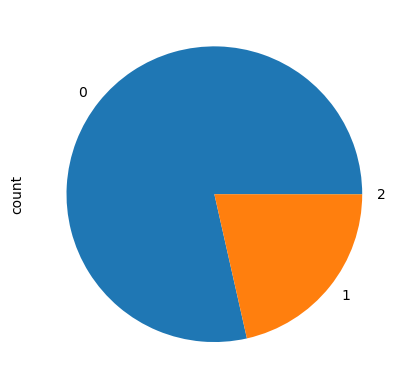

In [15]:
import matplotlib
get_ipython().magic("matplotlib inline")
model_data_l.clustor.value_counts().plot(kind = "pie")

- 用户细分

In [16]:
# - 1、进行变量分布的正态转换
import numpy as np
from sklearn import preprocessing

In [17]:
quantile_transformer = preprocessing.QuantileTransformer(output_distribution='normal', random_state=0)
fa_scores_trans=quantile_transformer.fit_transform(fa_scores)
fa_scores_trans=pd.DataFrame(fa_scores_trans)

In [18]:
fa_scores_trans=fa_scores_trans.rename(columns={0: "ATM_POS", 1: "TBM", 2: "CSC"})

In [19]:
# 查看变量的偏度
var = ["ATM_POS","TBM","CSC"]
skew_var = {}
for i in var:
    skew_var[i]=abs(fa_scores_trans[i].skew())
skew=pd.Series(skew_var).sort_values(ascending=False)
skew


TBM        0.012075
ATM_POS    0.011758
CSC        0.007694
dtype: float64

In [20]:
# - 2、进行 k-means聚类
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3) #MiniBatchKMeans()分批处理
#kmeans = cluster.KMeans(n_clusters=3, init='random', n_init=1)
result=kmeans.fit(fa_scores_trans)
#print(result)

In [21]:
# - 3、对分类结果进行解读
model_data_l=model_data.join(pd.DataFrame(result.
labels_))
model_data_l=model_data_l.rename(columns={0: "clustor"})
model_data_l.head()

,ID,CNT_TBM,CNT_ATM,CNT_POS,CNT_CSC,CNT_TOT,clustor
0,41360,34,3,3,9,49,0
1,52094,44,17,5,18,84,0
2,57340,122,26,32,36,216,0
3,76885,42,3,6,1,52,1
4,89150,20,15,2,2,39,1


In [22]:
model_data_l.clustor.value_counts()

clustor
1    35582
0    34385
2    30033
Name: count, dtype: int64

In [23]:
#聚类事后分析
from sklearn import tree
clf=tree.DecisionTreeClassifier(criterion='gini',max_depth=3, min_samples_split=100, min_samples_leaf=100,random_state=12345)
# 当前支持计算信息增益和 GINI
clf.fit(model_data, result.labels_)

DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, min_samples_split=100,
                       random_state=12345)

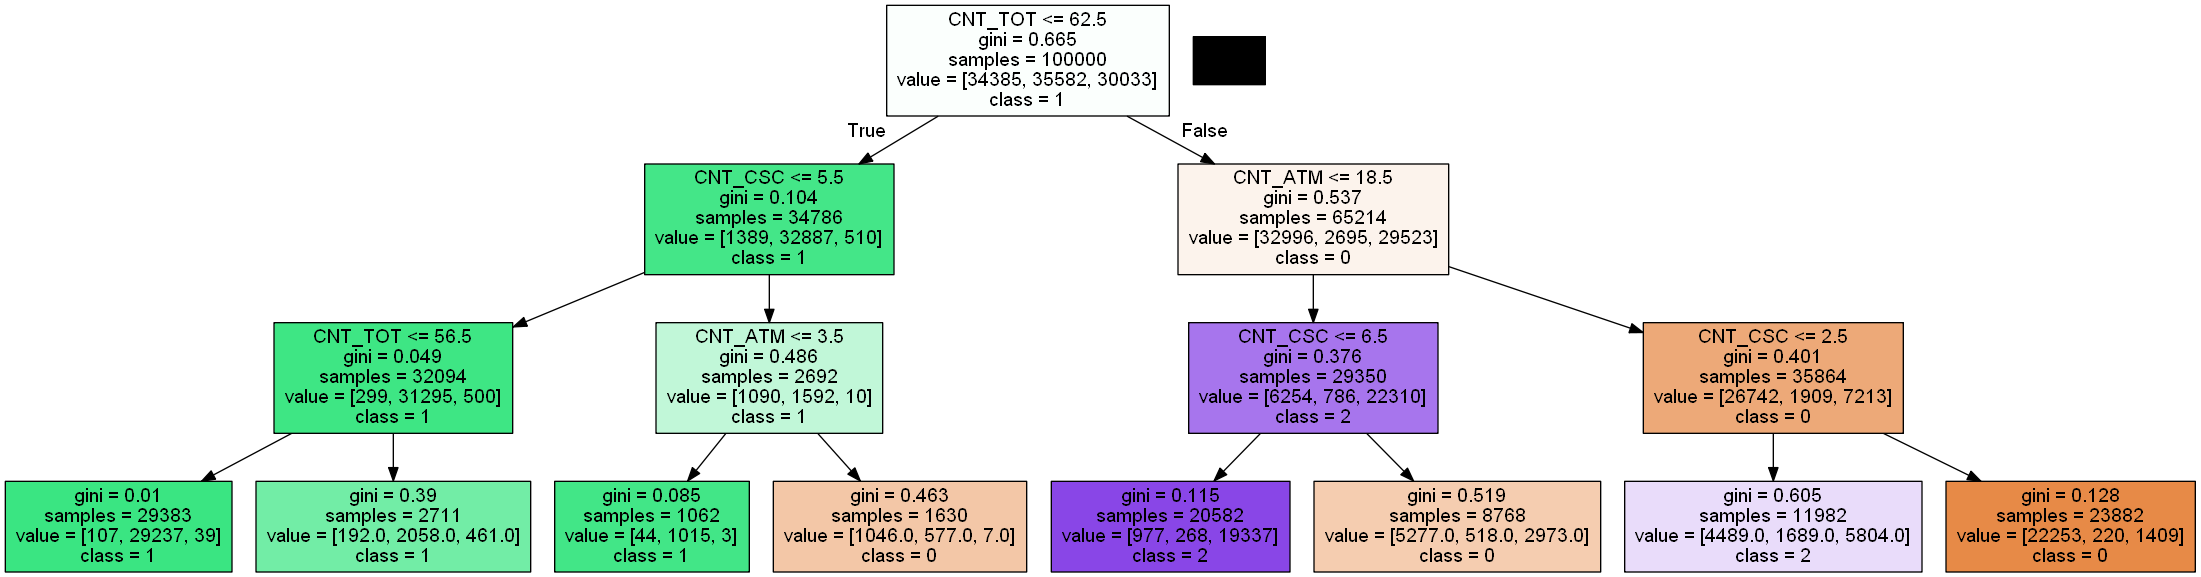

In [24]:
import pydotplus
from IPython.display import Image
import sklearn.tree as tree
dot_data = tree.export_graphviz(clf,out_file=None,feature_names=model_data.columns,class_names=["0","1","2"],filled=True)
graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())